In [ ]:
from pathlib import Path
PROJECT = Path(r'D:\tcc_ibov')
DIRS = {
    'raw':       PROJECT / 'data' / 'raw',
    'processed': PROJECT / 'data' / 'processed',
    'models':    PROJECT / 'models',
    'reports':   PROJECT / 'reports',
    'utils':     PROJECT / 'utils',
}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

# tcc_utils.py e gravado uma unica vez pelo notebook 00_setup -- aqui so importa.
import sys
sys.path.insert(0, str(DIRS['utils']))
import importlib, tcc_utils; importlib.reload(tcc_utils)
from tcc_utils import build_cutoffs, assign_trading_day

import pandas as pd
import numpy as np
print("Setup OK -- tcc_utils importado.")


In [3]:
corpus = pd.read_parquet(DIRS['raw'] / 'infomoney_corpus.parquet')
precos = pd.read_parquet(DIRS['processed'] / 'bvsp_clean.parquet')

cutoffs = build_cutoffs(pd.DatetimeIndex(precos.index))
corpus['trading_day'] = assign_trading_day(corpus['ts_utc'], cutoffs)

sem_bucket = corpus['trading_day'].isna().sum()
print(f"Sem bucket (após último corte da série): {sem_bucket} — descartadas")
corpus = corpus.dropna(subset=['trading_day'])

por_dia = corpus.groupby('trading_day').size()
todos_pregoes = pd.Series(0, index=precos.loc['2019-01-01':'2024-12-31'].index)
por_dia = por_dia.reindex(todos_pregoes.index, fill_value=0)

print(f"\nManchetes/pregão — mediana: {por_dia.median():.0f} | "
      f"média: {por_dia.mean():.1f} | min: {por_dia.min()} | max: {por_dia.max()}")
print(f"Pregões com ZERO manchetes: {(por_dia == 0).sum()} de {len(por_dia)}")
print(f"Pregões com < 5 manchetes: {(por_dia < 5).sum()}")

print("\nMediana de manchetes/pregão por ano:")
print(por_dia.groupby(por_dia.index.year).median())

corpus.to_parquet(DIRS['processed'] / 'corpus_bucketed.parquet')
print("\nSalvo: corpus_bucketed.parquet")

Sem bucket (após último corte da série): 44 — descartadas

Manchetes/pregão — mediana: 37 | média: 37.0 | min: 3 | max: 126
Pregões com ZERO manchetes: 0 de 1493
Pregões com < 5 manchetes: 1

Mediana de manchetes/pregão por ano:
Date
2019    17.0
2020    23.0
2021    37.0
2022    40.0
2023    47.0
2024    52.0
dtype: float64

Salvo: corpus_bucketed.parquet


Pregão mais magro:
Date
2019-07-18    3
dtype: int64


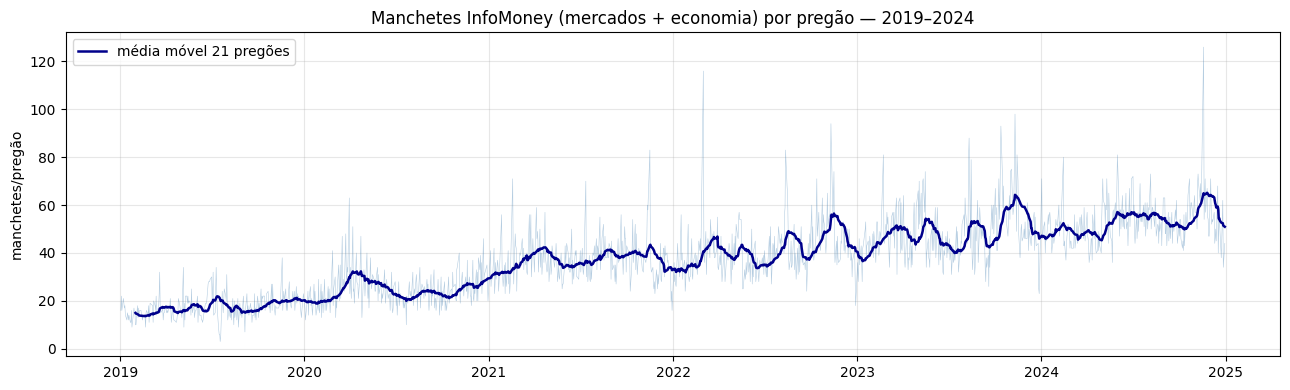

In [4]:
# O único pregão com < 5 manchetes — confirmar que é pré-feriado, não bug
print("Pregão mais magro:")
print(por_dia[por_dia < 5])

# Gráfico: manchetes por pregão ao longo do tempo, com média móvel
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(por_dia.index, por_dia.values, lw=0.4, alpha=0.4, color='steelblue')
ax.plot(por_dia.index, por_dia.rolling(21).mean(), lw=1.8, color='darkblue',
        label='média móvel 21 pregões')
ax.set_title('Manchetes InfoMoney (mercados + economia) por pregão — 2019–2024')
ax.set_ylabel('manchetes/pregão'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(DIRS['reports'] / 'manchetes_por_pregao.png', dpi=130)
plt.show()

In [5]:
!pip install -q transformers torch

import torch
from transformers import AutoTokenizer, AutoModel

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {DEVICE}")
assert DEVICE == 'cuda', "Sem GPU — ative T4 em Runtime > Change runtime type"

MODEL_NAME = 'neuralmind/bert-base-portuguese-cased'   # BERTimbau base
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE).eval()

@torch.no_grad()
def embed_batch(texts, max_len=64):
    """Mean-pooling mascarado dos tokens da última camada.
    max_len=64: manchete cabe inteira (medimos isso já já); trunca o raro
    outlier longo sem custo de padding excessivo."""
    enc = tokenizer(texts, padding=True, truncation=True,
                    max_length=max_len, return_tensors='pt').to(DEVICE)
    out = model(**enc).last_hidden_state          # (B, T, 768)
    mask = enc['attention_mask'].unsqueeze(-1).float()   # (B, T, 1)
    # média só sobre tokens reais (ignora padding via máscara)
    summed = (out * mask).sum(1)
    counts = mask.sum(1).clamp(min=1e-9)
    return (summed / counts).cpu().numpy()        # (B, 768)

# --- Sanidade: 5 manchetes, 2 claramente relacionadas ---
teste = [
    "Ibovespa fecha em alta com otimismo sobre cortes de juros",
    "Bolsa brasileira sobe puxada por expectativa de queda na Selic",  # ~sinônima da 1a
    "Petrobras anuncia aumento no preço da gasolina",
    "Copom eleva taxa Selic em 0,5 ponto percentual",
    "Receita de bolo de cenoura fica pronta em 40 minutos",           # off-topic
]
import numpy as np
V = embed_batch(teste)
print(f"Shape: {V.shape}  (esperado (5, 768))")

# Similaridade cosseno: as duas primeiras devem ser as mais parecidas;
# a receita de bolo, a mais distante das financeiras.
def cos(a, b): return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
print(f"\nsim(bolsa alta, bolsa sobe) = {cos(V[0], V[1]):.3f}   <- deve ser ALTA")
print(f"sim(bolsa alta, bolo)       = {cos(V[0], V[4]):.3f}   <- deve ser BAIXA")
print(f"sim(Selic Copom, Selic bolsa) = {cos(V[3], V[1]):.3f}")

Device: cuda


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

... (3 outputs left out)

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Shape: (5, 768)  (esperado (5, 768))

sim(bolsa alta, bolsa sobe) = 0.899   <- deve ser ALTA
sim(bolsa alta, bolo)       = 0.505   <- deve ser BAIXA
sim(Selic Copom, Selic bolsa) = 0.815


In [6]:
corpus = pd.read_parquet(DIRS['processed'] / 'corpus_bucketed.parquet')
corpus = corpus.sort_values('ts_utc').reset_index(drop=True)   # ordem temporal estável
print(f"Manchetes: {len(corpus):,}")

# Comprimento em TOKENS do BERTimbau (não em palavras — é o que o modelo vê)
lens = corpus['headline'].apply(lambda t: len(tokenizer.encode(t)))
print(f"\nTokens/manchete — mediana: {lens.median():.0f} | "
      f"p95: {lens.quantile(.95):.0f} | p99: {lens.quantile(.99):.0f} | max: {lens.max()}")
print(f"Manchetes > 64 tokens: {(lens > 64).sum()} ({(lens > 64).mean():.2%})")

Manchetes: 57,612

Tokens/manchete — mediana: 23 | p95: 38 | p99: 47 | max: 71
Manchetes > 64 tokens: 12 (0.02%)


In [7]:
from pathlib import Path
import numpy as np

EMB_DIR = DIRS['processed'] / 'embeddings_bertimbau'
EMB_DIR.mkdir(exist_ok=True)
BATCH = 128           # T4 aguenta; se der OOM, baixe p/ 64
CKPT_EVERY = 40       # salva a cada 40 lotes (~5120 manchetes)
MAX_LEN = 64          # ajuste conforme a célula 3

texts = corpus['headline'].tolist()
n = len(texts)
n_batches = (n + BATCH - 1) // BATCH

# Retomável: se já há shards salvos, começa do próximo
done = sorted(EMB_DIR.glob('emb_*.npy'))
start_batch = len(done) * CKPT_EVERY
if start_batch:
    print(f"Retomando: {len(done)} checkpoints, do lote {start_batch}")

buf = []
import time; t0 = time.time()
for b in range(start_batch, n_batches):
    lo, hi = b * BATCH, min((b + 1) * BATCH, n)
    buf.append(embed_batch(texts[lo:hi], max_len=MAX_LEN))

    if (b + 1) % CKPT_EVERY == 0 or b == n_batches - 1:
        shard = np.vstack(buf)
        idx = b // CKPT_EVERY
        np.save(EMB_DIR / f'emb_{idx:03d}.npy', shard)
        buf = []
        print(f"lote {b+1}/{n_batches} | ckpt {idx:03d} salvo | "
              f"{time.time()-t0:.0f}s")

print("Extração concluída.")

Retomando: 12 checkpoints, do lote 480
Extração concluída.


In [8]:
shards = sorted(EMB_DIR.glob('emb_*.npy'))
E = np.vstack([np.load(s) for s in shards])
print(f"Matriz de embeddings: {E.shape}  (esperado ({len(corpus)}, 768))")
assert E.shape[0] == len(corpus), "DESALINHAMENTO — nº de vetores != nº de manchetes"

# Salva a matriz crua alinhada 1:1 com corpus_bucketed (mesma ordem temporal).
# A agregação por dia (barata, CPU) acontece no próximo notebook a partir daqui.
np.save(DIRS['processed'] / 'emb_bertimbau_raw.npy', E)
print("Salvo: emb_bertimbau_raw.npy")

Matriz de embeddings: (57612, 768)  (esperado (57612, 768))
Salvo: emb_bertimbau_raw.npy


In [9]:
# Confirma que o crescimento veio da repesca, não de duplicação acidental
corpus = pd.read_parquet(DIRS['processed'] / 'corpus_bucketed.parquet')
print(f"Linhas no corpus: {len(corpus):,}")
print(f"URLs únicas: {corpus['url'].nunique():,}  <- deve ser IGUAL ao total")
print(f"Manchete+dia duplicados: "
      f"{corpus.duplicated(subset=['headline', 'trading_day']).sum()}")

# Recontagem rápida do censo, agora com o corpus final
por_dia = corpus.groupby('trading_day').size()
print(f"\nManchetes/pregão — mediana: {por_dia.median():.0f} | "
      f"total pregões cobertos: {corpus['trading_day'].nunique()}")

Linhas no corpus: 57,612
URLs únicas: 57,612  <- deve ser IGUAL ao total
Manchete+dia duplicados: 1

Manchetes/pregão — mediana: 35 | total pregões cobertos: 1615


In [10]:
dup = corpus[corpus.duplicated(subset=['headline', 'trading_day'], keep=False)]
print(dup[['headline', 'ts_utc', 'url']].to_string())

                                                        headline                    ts_utc                                                                                               url
77567  Raízen (RAIZ4) anuncia venda de projetos de energia solar 2024-12-20 22:52:18+00:00    https://www.infomoney.com.br/mercados/raizen-raiz4-anuncia-venda-de-projetos-de-energia-solar/
77577  Raízen (RAIZ4) anuncia venda de projetos de energia solar 2024-12-23 11:27:34+00:00  https://www.infomoney.com.br/mercados/raizen-raiz4-anuncia-venda-de-projetos-de-energia-solar-2/


In [11]:
import numpy as np

corpus = pd.read_parquet(DIRS['processed'] / 'corpus_bucketed.parquet').reset_index(drop=True)
E = np.load(DIRS['processed'] / 'emb_bertimbau_raw.npy')
assert len(corpus) == E.shape[0], "desalinhado antes de começar"

# Índice a remover: a 2ª ocorrência (a republicação com sufixo -2).
# keep='first' mantém a publicação original, marca as seguintes como dup.
dup_mask = corpus.duplicated(subset=['headline', 'trading_day'], keep='first')
drop_idx = corpus.index[dup_mask].tolist()
print(f"Removendo {len(drop_idx)} linha(s): índice {drop_idx}")

# Remove das DUAS estruturas pelo MESMO índice posicional -> alinhamento preservado
keep = ~dup_mask.values
corpus = corpus[keep].reset_index(drop=True)
E = E[keep]

assert len(corpus) == E.shape[0], "desalinhado após remoção"
print(f"Corpus: {len(corpus):,} | Embeddings: {E.shape}")
print(f"Duplicados restantes: {corpus.duplicated(subset=['headline','trading_day']).sum()}")

# Re-salva as duas versões limpas e alinhadas
corpus.to_parquet(DIRS['processed'] / 'corpus_bucketed.parquet')
np.save(DIRS['processed'] / 'emb_bertimbau_raw.npy', E)
print("Salvos (limpos e alinhados).")

Removendo 1 linha(s): índice [56566]
Corpus: 57,611 | Embeddings: (57611, 768)
Duplicados restantes: 0
Salvos (limpos e alinhados).


In [12]:
import numpy as np
import pandas as pd

corpus = pd.read_parquet(DIRS['processed'] / 'corpus_bucketed.parquet').reset_index(drop=True)
E = np.load(DIRS['processed'] / 'emb_bertimbau_raw.npy')
assert len(corpus) == E.shape[0]

# trading_day como chave de agrupamento (já é datetime64, normalizado p/ meia-noite)
dias = corpus['trading_day'].values
dias_unicos = np.array(sorted(pd.unique(dias)))
print(f"Pregões com notícia: {len(dias_unicos)}")

# Pré-computa índices por dia uma vez (evita groupby repetido sobre matriz grande)
from collections import defaultdict
idx_por_dia = defaultdict(list)
for i, d in enumerate(dias):
    idx_por_dia[d].append(i)

emb_mean, emb_disp, n_not, index_dias = [], [], [], []
for d in dias_unicos:
    idx = idx_por_dia[d]
    bloco = E[idx]                      # (n_d, 768) vetores do dia
    centroide = bloco.mean(axis=0)      # (768,) -> emb_mean
    # dispersão: distância média ao centroide (0 se só há 1 notícia no dia)
    disp = np.linalg.norm(bloco - centroide, axis=1).mean() if len(idx) > 1 else 0.0
    emb_mean.append(centroide)
    emb_disp.append(disp)
    n_not.append(len(idx))
    index_dias.append(d)

emb_mean = np.vstack(emb_mean)          # (n_dias, 768)
index_dias = pd.DatetimeIndex(index_dias)

# DataFrame de features textuais, uma linha por pregão
feat_txt = pd.DataFrame(
    emb_mean, index=index_dias,
    columns=[f'emb_{i:03d}' for i in range(768)]
)
feat_txt['n_noticias'] = n_not          # bruto — normalização walk-forward vem depois
feat_txt['emb_dispersao'] = emb_disp
feat_txt.index.name = 'trading_day'

print(f"Shape features textuais: {feat_txt.shape}  (esperado ({len(dias_unicos)}, 770))")
print(f"n_noticias — min {feat_txt['n_noticias'].min()} | "
      f"mediana {feat_txt['n_noticias'].median():.0f} | max {feat_txt['n_noticias'].max()}")
print(f"emb_dispersao — min {feat_txt['emb_dispersao'].min():.3f} | "
      f"mediana {feat_txt['emb_dispersao'].median():.3f}")
feat_txt.iloc[:3, -4:]   # espia as últimas colunas

Pregões com notícia: 1615
Shape features textuais: (1615, 770)  (esperado (1615, 770))
n_noticias — min 3 | mediana 35 | max 126
emb_dispersao — min 2.707 | mediana 3.939


,emb_766,emb_767,n_noticias,emb_dispersao
trading_day,,,,
2018-07-02,0.053935,-0.175657,26,4.040949
2018-07-03,0.039827,-0.235799,20,4.236609
2018-07-04,-0.047963,-0.135613,24,4.152074


In [13]:
precos = pd.read_parquet(DIRS['processed'] / 'bvsp_clean.parquet')

# Recorte do PERÍODO DE ESTUDO — o buffer de 2018 sai aqui, de forma explícita.
estudo = precos.loc['2019-01-01':'2024-12-31']
print(f"Pregões no estudo: {len(estudo)}")

# Alinha features textuais ao calendário de pregões do estudo.
# Pregão sem notícia (não deve haver, mas garantimos) -> tratamento explícito.
feat_estudo = feat_txt.reindex(estudo.index)
sem_texto = feat_estudo['n_noticias'].isna().sum()
print(f"Pregões do estudo SEM texto: {sem_texto}")

# Diagnóstico de cobertura: todo pregão do estudo tem embedding?
cobertura = feat_estudo['emb_000'].notna().mean()
print(f"Cobertura textual do estudo: {cobertura:.2%}")

# n_noticias ausente vira 0 (não houve notícia); emb_* ausente fica NaN
# e será tratado no notebook de modelagem (imputação/máscara) — NÃO aqui,
# para não inventar sinal antes de ver quantos casos são.
feat_estudo['n_noticias'] = feat_estudo['n_noticias'].fillna(0)

feat_estudo.to_parquet(DIRS['processed'] / 'features_texto_bertimbau.parquet')
print(f"\nSalvo: features_texto_bertimbau.parquet | shape {feat_estudo.shape}")

Pregões no estudo: 1493
Pregões do estudo SEM texto: 0
Cobertura textual do estudo: 100.00%

Salvo: features_texto_bertimbau.parquet | shape (1493, 770)


In [15]:
#@title FinBERT-PT-BR — carga + sanidade (CORRIGIDO: forward oficial do modelo)
# Correção: NÃO reconstruir a cabeça manualmente (deu logits sem sentido).
# Usamos a forward oficial fb_model(**enc).logits (caminho testado da doc) para
# sentimento, e fb_model.bert(**enc) para embeddings. Duas chamadas, ambas pelos
# caminhos que o modelo expõe — sem adivinhar a estrutura interna da cabeça.

import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, BertForSequenceClassification

FINBERT = 'lucas-leme/FinBERT-PT-BR'
fb_tok = AutoTokenizer.from_pretrained(FINBERT)
fb_model = BertForSequenceClassification.from_pretrained(FINBERT).to(DEVICE).eval()

# Mapa de classes: a doc AFIRMA 0=POS,1=NEG,2=NEU, mas vamos VERIFICAR
# empiricamente na sanidade em vez de confiar. config.id2label é a fonte real.
print("config.id2label do modelo:", fb_model.config.id2label)

@torch.no_grad()
def finbert_batch(texts, max_len=64):
    """probs (B,3) via forward OFICIAL; emb (B,768) via encoder .bert."""
    enc = fb_tok(texts, padding=True, truncation=True,
                 max_length=max_len, return_tensors='pt').to(DEVICE)
    logits = fb_model(**enc).logits                      # forward completa oficial
    probs = F.softmax(logits, dim=-1).cpu().numpy()
    hidden = fb_model.bert(**enc).last_hidden_state
    mask = enc['attention_mask'].unsqueeze(-1).float()
    emb = ((hidden * mask).sum(1) / mask.sum(1).clamp(min=1e-9)).cpu().numpy()
    return probs, emb

teste = [
    "Ibovespa dispara e fecha no maior nível da história",      # deve ser POS
    "Bolsa desaba com temor de recessão e fuga de capital",     # deve ser NEG
    "Comitê mantém taxa de juros inalterada, como esperado",    # deve ser NEU
    "Petrobras anuncia lucro recorde no trimestre",             # deve ser POS
    "Empresa entra com pedido de recuperação judicial",         # deve ser NEG
]
probs, emb = finbert_batch(teste)
print(f"\nEmbeddings: {emb.shape} | Probs: {probs.shape}\n")
id2label = fb_model.config.id2label
for t, p in zip(teste, probs):
    lab = id2label[int(p.argmax())]
    dist = " ".join(f"{id2label[i]}={p[i]:.2f}" for i in range(3))
    print(f"  [{lab}] {dist} | {t[:50]}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

config.id2label do modelo: {0: 'POSITIVE', 1: 'NEGATIVE', 2: 'NEUTRAL'}

Embeddings: (5, 768) | Probs: (5, 3)

  [POSITIVE] POSITIVE=0.91 NEGATIVE=0.05 NEUTRAL=0.04 | Ibovespa dispara e fecha no maior nível da históri
  [NEGATIVE] POSITIVE=0.03 NEGATIVE=0.94 NEUTRAL=0.03 | Bolsa desaba com temor de recessão e fuga de capit
  [NEGATIVE] POSITIVE=0.12 NEGATIVE=0.72 NEUTRAL=0.16 | Comitê mantém taxa de juros inalterada, como esper
  [POSITIVE] POSITIVE=0.91 NEGATIVE=0.05 NEUTRAL=0.04 | Petrobras anuncia lucro recorde no trimestre
  [NEGATIVE] POSITIVE=0.04 NEGATIVE=0.88 NEUTRAL=0.08 | Empresa entra com pedido de recuperação judicial


In [16]:
#@title Extração FinBERT-PT-BR em massa (57.611 manchetes) · sentimento + embeddings
# Uma passada produz os insumos das DUAS vias: probs de sentimento (Via 2) e
# embeddings do encoder (Via 1). Checkpoint a cada CKPT_EVERY lotes (retomável).
# corpus JÁ está alinhado e limpo (mesmo do BERTimbau) -> alinhamento 1:1 garantido.

corpus = pd.read_parquet(DIRS['processed'] / 'corpus_bucketed.parquet').reset_index(drop=True)
texts = corpus['headline'].tolist()
n = len(texts)
print(f"Manchetes a processar: {n:,}")

FB_DIR = DIRS['processed'] / 'finbert_extract'
FB_DIR.mkdir(exist_ok=True)
BATCH = 128
CKPT_EVERY = 40
MAX_LEN = 64

n_batches = (n + BATCH - 1) // BATCH
done = sorted(FB_DIR.glob('probs_*.npy'))
start_batch = len(done) * CKPT_EVERY
if start_batch:
    print(f"Retomando: {len(done)} checkpoints, do lote {start_batch}")

buf_probs, buf_emb = [], []
import time; t0 = time.time()
for b in range(start_batch, n_batches):
    lo, hi = b * BATCH, min((b + 1) * BATCH, n)
    p, e = finbert_batch(texts[lo:hi], max_len=MAX_LEN)
    buf_probs.append(p); buf_emb.append(e)
    if (b + 1) % CKPT_EVERY == 0 or b == n_batches - 1:
        idx = b // CKPT_EVERY
        np.save(FB_DIR / f'probs_{idx:03d}.npy', np.vstack(buf_probs))
        np.save(FB_DIR / f'emb_{idx:03d}.npy', np.vstack(buf_emb))
        buf_probs, buf_emb = [], []
        print(f"lote {b+1}/{n_batches} | ckpt {idx:03d} | {time.time()-t0:.0f}s")
print("Extração concluída.")

# Consolida e valida alinhamento 1:1 com corpus
probs = np.vstack([np.load(s) for s in sorted(FB_DIR.glob('probs_*.npy'))])
emb   = np.vstack([np.load(s) for s in sorted(FB_DIR.glob('emb_*.npy'))])
print(f"\nProbs: {probs.shape} (esperado ({n}, 3)) | Emb: {emb.shape} (esperado ({n}, 768))")
assert probs.shape[0] == n and emb.shape[0] == n, "DESALINHAMENTO"

np.save(DIRS['processed'] / 'finbert_probs_raw.npy', probs)
np.save(DIRS['processed'] / 'finbert_emb_raw.npy', emb)
print("Salvos: finbert_probs_raw.npy, finbert_emb_raw.npy")

Manchetes a processar: 57,611
lote 40/451 | ckpt 000 | 22s
lote 80/451 | ckpt 001 | 45s
lote 120/451 | ckpt 002 | 70s
lote 160/451 | ckpt 003 | 97s
lote 200/451 | ckpt 004 | 126s
lote 240/451 | ckpt 005 | 155s
lote 280/451 | ckpt 006 | 187s
lote 320/451 | ckpt 007 | 218s
lote 360/451 | ckpt 008 | 248s
lote 400/451 | ckpt 009 | 271s
lote 440/451 | ckpt 010 | 292s
lote 451/451 | ckpt 011 | 298s
Extração concluída.

Probs: (57611, 3) (esperado (57611, 3)) | Emb: (57611, 768) (esperado (57611, 768))
Salvos: finbert_probs_raw.npy, finbert_emb_raw.npy


In [17]:
#@title Via 2 — agregação de sentimento FinBERT-PT-BR por pregão (4 features)
# Transforma probs (57611,3) [POS,NEG,NEU] em 4 features/pregão, densas e
# interpretáveis. Usa trading_day (corte 17h) -> sentimento do dia t vem só de
# notícias até o corte. Alinha ao índice do estudo (como features_preco).

corpus = pd.read_parquet(DIRS['processed'] / 'corpus_bucketed.parquet').reset_index(drop=True)
probs = np.load(DIRS['processed'] / 'finbert_probs_raw.npy')
assert len(corpus) == len(probs), "desalinhado"

# Polaridade por manchete = P(pos) - P(neg). Ignora neutro (é o "sem sinal").
polaridade = probs[:, 0] - probs[:, 1]        # (n,) em [-1, +1]
pred_classe = probs.argmax(axis=1)            # 0=pos,1=neg,2=neu

df_sent = pd.DataFrame({
    'trading_day': corpus['trading_day'].values,
    'polaridade': polaridade,
    'is_pos': (pred_classe == 0).astype(int),
    'is_neg': (pred_classe == 1).astype(int),
})

# Agregação por pregão
g = df_sent.groupby('trading_day')
feat_sent = pd.DataFrame({
    'sent_polaridade': g['polaridade'].mean(),      # humor líquido médio do dia
    'sent_dispersao':  g['polaridade'].std(),       # divisão do noticiário
    'sent_pos_frac':   g['is_pos'].mean(),          # fração de manchetes positivas
    'sent_neg_frac':   g['is_neg'].mean(),          # fração de manchetes negativas
})
# dias com 1 só notícia -> std NaN -> 0 (sem dispersão definível)
feat_sent['sent_dispersao'] = feat_sent['sent_dispersao'].fillna(0)

# Alinha ao índice do estudo
feat_preco = pd.read_parquet(DIRS['processed'] / 'features_preco.parquet')
feat_sent = feat_sent.reindex(feat_preco.index)
print(f"Cobertura (deve ser 100%): {feat_sent['sent_polaridade'].notna().mean():.1%}")
print(f"NaN por coluna:\n{feat_sent.isna().sum()}")

# Estatísticas descritivas (sanidade + material p/ o TCC)
print(f"\nsent_polaridade — média {feat_sent['sent_polaridade'].mean():+.3f} | "
      f"min {feat_sent['sent_polaridade'].min():+.3f} | "
      f"max {feat_sent['sent_polaridade'].max():+.3f}")
print(f"Fração média de manchetes: pos {feat_sent['sent_pos_frac'].mean():.1%} | "
      f"neg {feat_sent['sent_neg_frac'].mean():.1%}")

# Correlação com o alvo (o teste que importa): sentimento de hoje prevê retorno D+1?
alvo = feat_preco['y']
print("\nCorrelação sentimento(t) -> retorno(t+1):")
for c in feat_sent.columns:
    corr = feat_sent[c].corr(alvo)
    print(f"  {c}: {corr:+.4f}")

# Correlação CONTEMPORÂNEA (sentimento de hoje vs retorno de hoje) — sanidade:
# deve ser positiva e MAIOR que a preditiva (sentimento reflete o que já aconteceu)
ret_hoje = feat_preco['ret_lag0']
print(f"\nSanidade — sent_polaridade(t) vs retorno(t) [contemporâneo]: "
      f"{feat_sent['sent_polaridade'].corr(ret_hoje):+.4f}")

feat_sent.to_parquet(DIRS['processed'] / 'features_sentimento_finbert.parquet')
print("\nSalvo: features_sentimento_finbert.parquet")

Cobertura (deve ser 100%): 100.0%
NaN por coluna:
sent_polaridade    0
sent_dispersao     0
sent_pos_frac      0
sent_neg_frac      0
dtype: int64

sent_polaridade — média -0.284 | min -0.803 | max +0.353
Fração média de manchetes: pos 21.3% | neg 53.2%

Correlação sentimento(t) -> retorno(t+1):
  sent_polaridade: -0.0390
  sent_dispersao: -0.0392
  sent_pos_frac: -0.0275
  sent_neg_frac: +0.0333

Sanidade — sent_polaridade(t) vs retorno(t) [contemporâneo]: +0.2014

Salvo: features_sentimento_finbert.parquet


In [ ]:
#@title Via 1 -- agregacao de embeddings FinBERT-PT-BR por pregao (768 dims)
# Espelha a agregacao do BERTimbau (celulas 10-11): mean-pooling por trading_day
# + dispersao (norma media ao centroide) + n_noticias, depois reindexado ao
# periodo de estudo (2019-01 a 2024-12, buffer de 2018 descartado). Fecha a
# simetria da comparacao BERTimbau vs FinBERT (Via 1 vs nivel 5).
# finbert_emb_raw.npy esta alinhado 1:1 com corpus_bucketed.parquet.

import numpy as np
import pandas as pd
from collections import defaultdict

corpus = pd.read_parquet(DIRS['processed'] / 'corpus_bucketed.parquet').reset_index(drop=True)
E = np.load(DIRS['processed'] / 'finbert_emb_raw.npy')
assert len(corpus) == E.shape[0], "desalinhado -- finbert_emb_raw.npy vs corpus_bucketed"

dias = corpus['trading_day'].values
dias_unicos = np.array(sorted(pd.unique(dias)))
print(f"Pregoes com noticia: {len(dias_unicos)}")

idx_por_dia = defaultdict(list)
for i, d in enumerate(dias):
    idx_por_dia[d].append(i)

emb_mean, emb_disp, n_not, index_dias = [], [], [], []
for d in dias_unicos:
    idx = idx_por_dia[d]
    bloco = E[idx]
    centroide = bloco.mean(axis=0)
    disp = np.linalg.norm(bloco - centroide, axis=1).mean() if len(idx) > 1 else 0.0
    emb_mean.append(centroide)
    emb_disp.append(disp)
    n_not.append(len(idx))
    index_dias.append(d)

emb_mean = np.vstack(emb_mean)
index_dias = pd.DatetimeIndex(index_dias)

feat_txt_fb = pd.DataFrame(
    emb_mean, index=index_dias,
    columns=[f'emb_{i:03d}' for i in range(768)]
)
feat_txt_fb['n_noticias'] = n_not
feat_txt_fb['emb_dispersao'] = emb_disp
feat_txt_fb.index.name = 'trading_day'
print(f"Shape (todos os dias com noticia): {feat_txt_fb.shape}")

# Recorte do periodo de estudo -- mesmo tratamento do BERTimbau (celula 11).
precos = pd.read_parquet(DIRS['processed'] / 'bvsp_clean.parquet')
estudo = precos.loc['2019-01-01':'2024-12-31']
feat_estudo_fb = feat_txt_fb.reindex(estudo.index)
sem_texto = feat_estudo_fb['n_noticias'].isna().sum()
cobertura = feat_estudo_fb['emb_000'].notna().mean()
print(f"Pregoes do estudo SEM texto: {sem_texto} | cobertura: {cobertura:.2%}")
feat_estudo_fb['n_noticias'] = feat_estudo_fb['n_noticias'].fillna(0)

feat_estudo_fb.to_parquet(DIRS['processed'] / 'features_texto_finbert.parquet')
print(f"
Salvo: features_texto_finbert.parquet | shape {feat_estudo_fb.shape}")
